<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/imbalanced%20data/seminar_note_6_1_imbalance_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **불균형데이터(Imbalanced Data)의 예측 성능**

<img src="https://assets.insightmediagroup.io/media/wp-content/uploads/2019/02/1ZeGXHtNu8fu_PswjHivGwg.jpeg">

In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np

## Threshold value에 따른 변화
<img src='https://www.jeremyjordan.me/content/images/2018/11/roc_cutoff-1.gif'>

# **PR graph의 중요성**
- **AUROC vs. PRAUC**

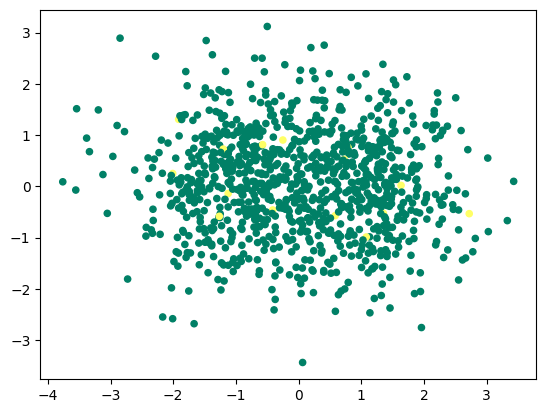

In [2]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000,
                           n_classes=2,
                           weights=[0.99, 0.01],
                           random_state=1)

plt.scatter(X[:, 0], X[:, 1], c=y, s=20, cmap='summer')

In [3]:
X.shape

(1000, 20)

In [7]:
from sklearn import preprocessing, model_selection, metrics, pipeline

X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y,
                                                                    test_size = 0.5,
                                                                    random_state = 2,
                                                                    stratify=y)

print(f'Dataset: Class 0(음성)= {len(y[y==0])} 개, Class1(양성)={len(y[y==1])} 개')
print(f'Train set: Class 0(음성)= {len(y_train[y_train==0])} 개, Class1(양성)={len(y_train[y_train==1])} 개')
print(f'Test set: Class 0(음성)= {len(y_test[y_test==0])} 개, Class1(양성)={len(y_test[y_test==1])} 개')

Dataset: Class 0(음성)= 985 개, Class1(양성)=15 개
Train set: Class 0(음성)= 492 개, Class1(양성)=8 개
Test set: Class 0(음성)= 493 개, Class1(양성)=7 개


In [19]:
pos_ratio = np.mean(y_test)*100
print(f"양성비율: {pos_ratio:.3f} %")

양성비율: 1.400 %


In [20]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(solver='lbfgs')
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

target_names = ['Negative (0)', 'Positive(1)']
print(metrics.classification_report(y_test, y_pred, target_names=target_names))

LogisticRegression()

              precision    recall  f1-score   support

Negative (0)       0.99      1.00      0.99       493
 Positive(1)       0.00      0.00      0.00         7

    accuracy                           0.99       500
   macro avg       0.49      0.50      0.50       500
weighted avg       0.97      0.99      0.98       500



In [22]:
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,


- 사이킷런 내부 모델의 의사결정임계값은 '0.5'로 예측 모델의 결과인 500개 모두 음성판정

Text(0.5, 1.0, 'ROC Curve (AUROC)')

Text(0.5, 1.0, 'Precision-Recall Curve')

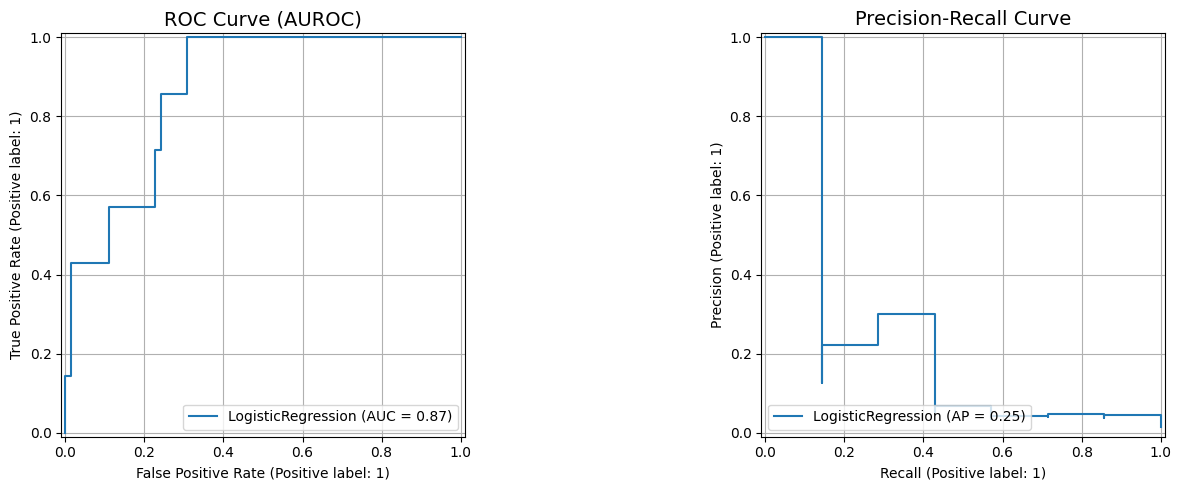

In [10]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

# AUROC 및 PR 커브 시각화 추가
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

RocCurveDisplay.from_estimator(clf, X_test, y_test, ax=axes[0])
axes[0].set_title('ROC Curve (AUROC)', fontsize=14)
axes[0].grid(True)

PrecisionRecallDisplay.from_estimator(clf, X_test, y_test, ax=axes[1])
axes[1].set_title('Precision-Recall Curve', fontsize=14)
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import roc_auc_score, average_precision_score

pos_ratio = np.mean(y_test)
auroc = roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1])
pr_auc = average_precision_score(y_test, clf.predict_proba(X_test)[:, 1])

print(f"AUROC Score: {auroc:.4f}")
print(f"PR-AUC Score: {pr_auc:.4f}")
print(f"양성비율: {pos_ratio:.4f}")

AUROC Score: 0.8690
PR-AUC Score: 0.2464
양성비율: 0.0140


- 불균형데이터의 AUROC는 의미 없음(예측 성능지표는 PRAUC)
- PR 그래프는 소수 범주 자료(양성, 1%)에 집중하는 반면 ROC curve는 음성과 양성 범주 자료를 모두 고려하기 때문

In [29]:
from sklearn.metrics import precision_recall_curve, f1_score

y_probs = clf.predict_proba(X_test)
y_probs.round(3)

array([[0.958, 0.042],
       [0.999, 0.001],
       [0.993, 0.007],
       [0.971, 0.029],
       [1.   , 0.   ],
       [0.976, 0.024],
       [0.993, 0.007],
       [0.99 , 0.01 ],
       [0.995, 0.005],
       [0.998, 0.002],
       [0.992, 0.008],
       [1.   , 0.   ],
       [0.976, 0.024],
       [0.997, 0.003],
       [0.999, 0.001],
       [0.975, 0.025],
       [0.991, 0.009],
       [0.987, 0.013],
       [0.974, 0.026],
       [0.997, 0.003],
       [0.999, 0.001],
       [0.993, 0.007],
       [0.994, 0.006],
       [1.   , 0.   ],
       [0.963, 0.037],
       [0.986, 0.014],
       [0.992, 0.008],
       [0.993, 0.007],
       [0.981, 0.019],
       [0.997, 0.003],
       [0.983, 0.017],
       [0.999, 0.001],
       [0.999, 0.001],
       [0.994, 0.006],
       [0.968, 0.032],
       [0.995, 0.005],
       [0.984, 0.016],
       [0.996, 0.004],
       [0.985, 0.015],
       [0.999, 0.001],
       [0.994, 0.006],
       [0.982, 0.018],
       [0.996, 0.004],
       [0.9

In [48]:
from collections import Counter
Counter(y_pred)

Counter({np.int64(0): 500})

(array([187., 115.,  51.,  42.,  28.,  23.,  17.,   9.,   7.,   5.,   1.,
          0.,   2.,   0.,   2.,   2.,   0.,   4.,   0.,   0.,   2.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   1.,   0.,   0.,   0.,   1.]),
 array([3.81711418e-05, 4.47466904e-03, 8.91116694e-03, 1.33476648e-02,
        1.77841627e-02, 2.22206606e-02, 2.66571585e-02, 3.10936564e-02,
        3.55301543e-02, 3.99666522e-02, 4.44031501e-02, 4.88396480e-02,
        5.32761459e-02, 5.77126438e-02, 6.21491417e-02, 6.65856396e-02,
        7.10221375e-02, 7.54586354e-02, 7.98951333e-02, 8.43316312e-02,
        8.87681291e-02, 9.32046270e-02, 9.76411249e-02, 1.02077623e-01,
        1.06514121e-01, 1.10950619e-01, 1.15387117e-01, 1.19823614e-01,
        1.24260112e-01, 1.28696610e-01, 1.33133108e-01, 1.37569606e-01,
        1.42006104e-01, 1.46442602e-01, 1.50879100e-01, 1.55315598e-01,
        1.

Text(0.5, 1.0, 'Probability Distribution (Predict Positive: 1)')

Text(0.5, 0, 'Predicted Positive Probability')

Text(0, 0.5, 'Frequency')

(array([  1.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   2.,   0.,   0.,   4.,
          0.,   2.,   2.,   0.,   2.,   0.,   1.,   5.,   7.,   9.,  17.,
         23.,  28.,  42.,  51., 115., 187.]),
 array([0.77813693, 0.78257343, 0.78700993, 0.79144643, 0.79588293,
        0.80031942, 0.80475592, 0.80919242, 0.81362892, 0.81806542,
        0.82250191, 0.82693841, 0.83137491, 0.83581141, 0.8402479 ,
        0.8446844 , 0.8491209 , 0.8535574 , 0.8579939 , 0.86243039,
        0.86686689, 0.87130339, 0.87573989, 0.88017639, 0.88461288,
        0.88904938, 0.89348588, 0.89792238, 0.90235888, 0.90679537,
        0.91123187, 0.91566837, 0.92010487, 0.92454136, 0.92897786,
        0.93341436, 0.93785086, 0.94228736, 0.94672385, 0.95116035,
        0.95559685, 0.96003335, 0.96446985, 0.96890634, 0.97334284,
        0.97777934, 0.98221584, 0.98665234, 0.

Text(0.5, 1.0, 'Probability Distribution (Predict Negative: 0)')

Text(0.5, 0, 'Predicted Positive Probability')

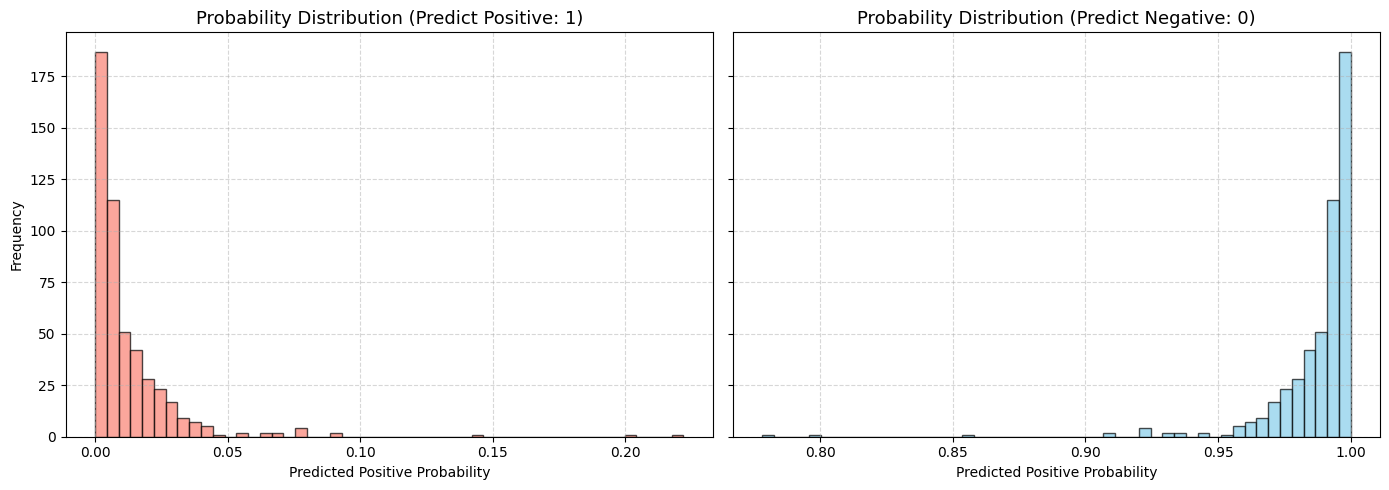

In [39]:
# @title 양성으로 판정할 확률이 0.5가 넘는 예측 값이 전혀 없음

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# 1. 양성(1) 예측 확률
axes[0].hist(y_probs[:, 1], bins=50, color='salmon', edgecolor='black', alpha=0.7)
axes[0].set_title('Probability Distribution (Predict Positive: 1)', fontsize=13)
axes[0].set_xlabel('Predicted Positive Probability')
axes[0].set_ylabel('Frequency')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. 음성(0) 예측 확률
axes[1].hist(y_probs[:, 0], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[1].set_title('Probability Distribution (Predict Negative: 0)', fontsize=13)
axes[1].set_xlabel('Predicted Positive Probability')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [43]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs[:, 1])

# Thresholds 길이에 맞춰 F1 Score 계산 (precision_recall_curve는 마지막에 1.0이 추가됨)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-8)

# F1-Score가 최대가 되는 지점 찾기
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"최적 임계값 (Best Threshold): {best_threshold:.4f}")
print(f"최고 F1-Score: {best_f1:.4f}")
print(f"해당 지점 Precision: {precisions[best_idx]:.4f}")
print(f"해당 지점 Recall: {recalls[best_idx]:.4f}")

# 최적 임계값을 적용한 최종 예측값 변환 예시 (y_probs[:, 1] 사용)
y_pred_custom = (y_probs[:, 1] >= best_threshold).astype(int)

최적 임계값 (Best Threshold): 0.0676
최고 F1-Score: 0.3529
해당 지점 Precision: 0.3000
해당 지점 Recall: 0.4286


<Figure size 1500x500 with 0 Axes>

Text(0.5, 1.0, 'Precision, Recall, F1-Score vs Threshold')

Text(0.5, 0, 'Threshold')

Text(0, 0.5, 'Score')

(0.0, 1.0)

(0.0, 1.05)

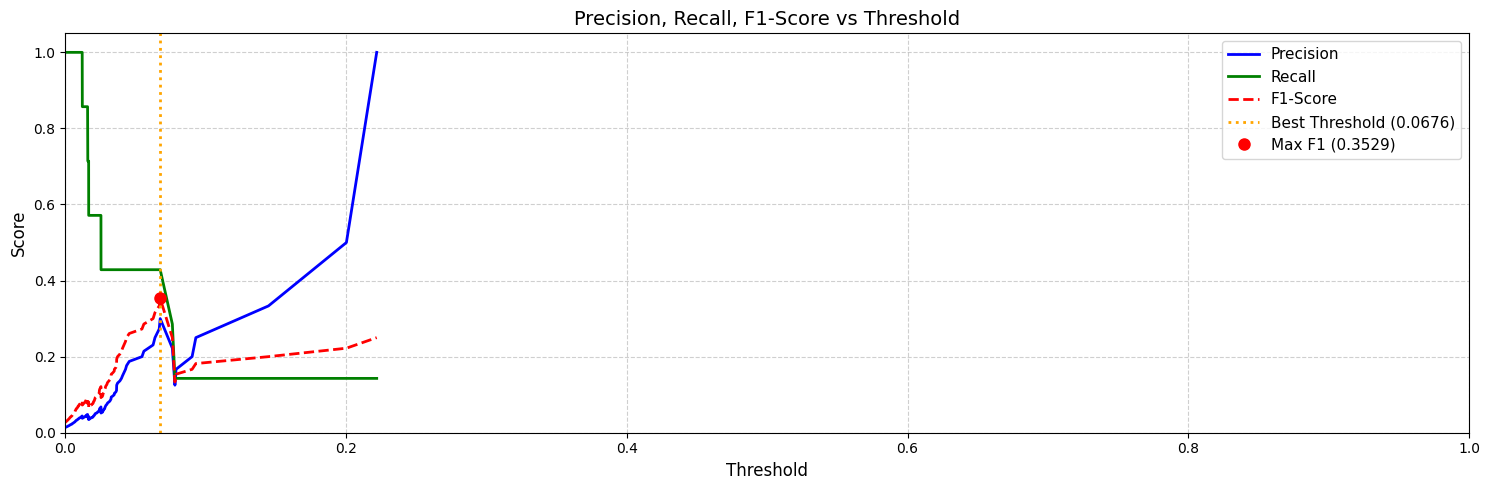

In [46]:
plt.figure(figsize=(15, 5))

plt.plot(thresholds, precisions[:-1], label='Precision', color='blue', linewidth=2)
plt.plot(thresholds, recalls[:-1], label='Recall', color='green', linewidth=2)
plt.plot(thresholds, f1_scores, label='F1-Score', color='red', linewidth=2, linestyle='--')

plt.axvline(x=best_threshold, color='orange', linestyle=':', linewidth=2,
            label=f'Best Threshold ({best_threshold:.4f})')
plt.plot(best_threshold, best_f1, 'ro', markersize=8, label=f'Max F1 ({best_f1:.4f})')

plt.title('Precision, Recall, F1-Score vs Threshold', fontsize=14)
plt.xlabel('Threshold', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.grid(True, linestyle='--', alpha=0.6)

# ★ 레전드를 오른쪽 위에 배치
plt.legend(loc='upper right', fontsize=11)

plt.tight_layout()
plt.show()

# **Imbalanced_classification**

## **Probability Threshold Moving**
## **1.  Optimal Threshold for ROC Curve**

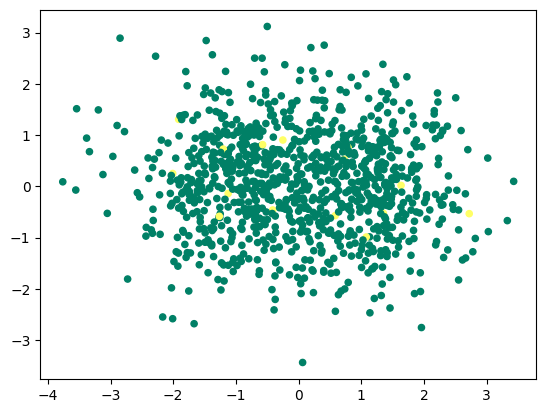

In [59]:
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=1000,
                           n_classes=2,
                           weights=[0.99, 0.01],
                           random_state=1)
plt.scatter(X[:, 0], X[:, 1], c=y, s=20, cmap='summer')

In [60]:
from collections import Counter

# y의 0과 1 개수 확인
counts = Counter(y)
print(f"Negative (0): {counts[0]} ({counts[0]/len(y)*100:.2f}%)")
print(f"Positive (1): {counts[1]} ({counts[1]/len(y)*100:.2f}%)")

Negative (0): 985 (98.50%)
Positive (1): 15 (1.50%)


The Geometric Mean or G-mean is a metric for imbalanced classification that, if optimized, will seek a balance between the sensitivity and
the specificity. One approach would be to test the model with each threshold returned from the call roc auc score() and select the threshold with the largest G-mean value.

In [61]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y,
                                                                    test_size=0.5,
                                                                    random_state=2,
                                                                    stratify=y)
model = LogisticRegression(solver='lbfgs')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_probas = model.predict_proba(X_test)

print(metrics.classification_report(y_test, y_pred, target_names=target_names))

LogisticRegression()

              precision    recall  f1-score   support

Negative (0)       0.99      1.00      0.99       493
 Positive(1)       0.00      0.00      0.00         7

    accuracy                           0.99       500
   macro avg       0.49      0.50      0.50       500
weighted avg       0.97      0.99      0.98       500



In [62]:
y_probas.round(2)

array([[0.96, 0.04],
       [1.  , 0.  ],
       [0.99, 0.01],
       [0.97, 0.03],
       [1.  , 0.  ],
       [0.98, 0.02],
       [0.99, 0.01],
       [0.99, 0.01],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [0.99, 0.01],
       [1.  , 0.  ],
       [0.98, 0.02],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [0.97, 0.03],
       [0.99, 0.01],
       [0.99, 0.01],
       [0.97, 0.03],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [0.99, 0.01],
       [0.99, 0.01],
       [1.  , 0.  ],
       [0.96, 0.04],
       [0.99, 0.01],
       [0.99, 0.01],
       [0.99, 0.01],
       [0.98, 0.02],
       [1.  , 0.  ],
       [0.98, 0.02],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [0.99, 0.01],
       [0.97, 0.03],
       [0.99, 0.01],
       [0.98, 0.02],
       [1.  , 0.  ],
       [0.99, 0.01],
       [1.  , 0.  ],
       [0.99, 0.01],
       [0.98, 0.02],
       [1.  , 0.  ],
       [0.97, 0.03],
       [1.  , 0.  ],
       [1.  , 0.  ],
       [0.98, 0.02],
       [0.99,

<Figure size 1200x600 with 0 Axes>

Text(0.5, 1.0, 'Scatter Plot of Prediction Probabilities by Actual Class')

Text(0.5, 0, 'Sample Index')

Text(0, 0.5, 'Positive Prediction Probability')

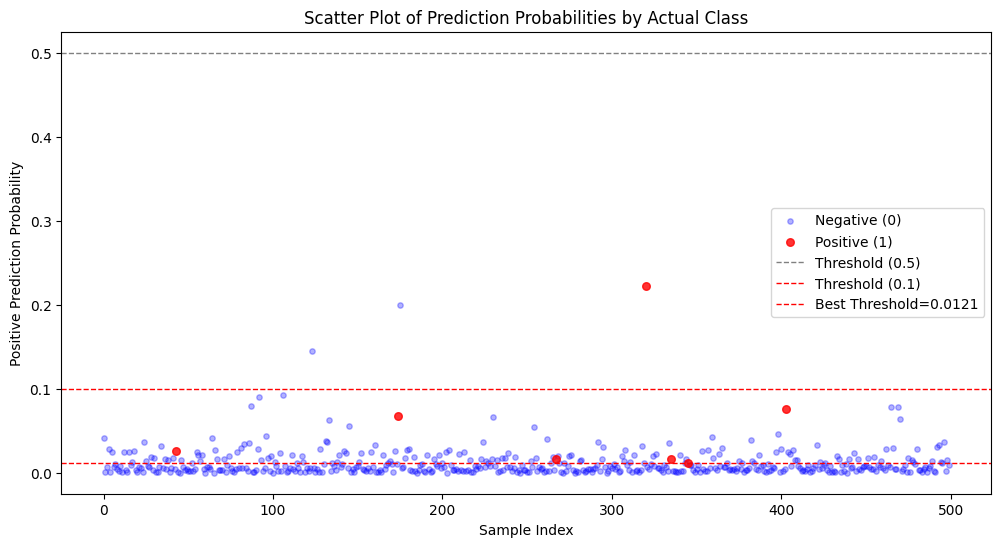

In [68]:
x_indices = np.arange(len(y_test))

plt.figure(figsize=(12, 6))

plt.scatter(x_indices[y_test == 0], y_probas[y_test == 0, 1],
            color='blue', alpha=0.3, s=15, label='Negative (0)')
plt.scatter(x_indices[y_test == 1], y_probas[y_test == 1, 1],
            color='red', alpha=0.8, s=30, label='Positive (1)')

# 분류 기준 임계값(예: 0.5) 선 추가
plt.axhline(y=0.5, color='gray', linestyle='--', linewidth=1, label='Threshold (0.5)')
plt.axhline(y=0.1, color='red', linestyle='--', linewidth=1, label='Threshold (0.1)')
plt.axhline(y=0.012053322313312301, color='red', linestyle='--', linewidth=1, label='Best Threshold=0.0121')

plt.title('Scatter Plot of Prediction Probabilities by Actual Class')
plt.xlabel('Sample Index')
plt.ylabel('Positive Prediction Probability')
plt.legend(loc='center right')
plt.show()

In [67]:
fpr, tpr, thresholds = metrics.roc_curve(y_test, y_probas[:, 1])
gmeans = np.sqrt(tpr * (1-fpr)) # calculate the g-mean for each threshold
ix = np.argmax(gmeans) # locate the index of the largest g-mean
print(f'Best Threshold={thresholds[ix]}, G-mean={gmeans[ix]}')

Best Threshold=0.012053322313312301, G-mean=0.8316751589290834


Text(0.5, 0, 'False Positive Rate')

Text(0, 0.5, 'True Positive Rate')

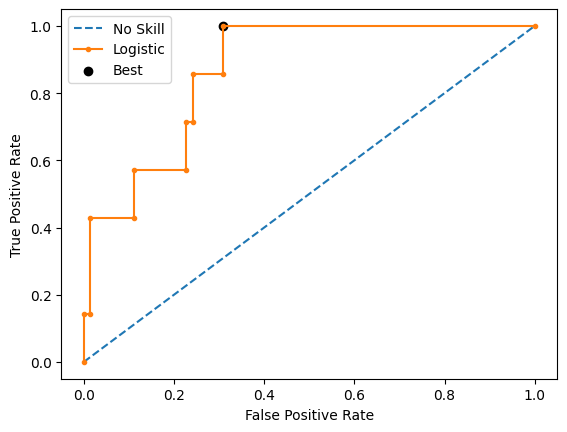

In [70]:
plt.plot([0,1], [0,1], linestyle='--', label='No Skill')
plt.plot(fpr, tpr, marker='.', label='Logistic')
plt.scatter(fpr[ix], tpr[ix], marker='o', color='black', label='Best')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend()

It turns out there is a much faster way to get the same result, called the Youden’s J statistic. The statistic is calculated as:
### J = Sensitivity + Specificity − 1 = Sensitivity + (1 − FalsePositiveRate) − 1 =  TruePositiveRate − FalsePositiveRate

In [71]:
J = tpr - fpr
ix = np.argmax(J)
best_thresh = thresholds[ix]
print(f'Best Threshold= {best_thresh}')

Best Threshold= 0.012053322313312301


## 2. Optimal Threshold for Precision-Recall Curve
### 2. 1 Unlike the ROC Curve, a precision-recall curve focuses on the performance of a classifier on the positive (minority class) only.

Best Threshold=  0.068, F-measure= 0.353

Precision=  0.300, Recall=  0.429

No Skill=  0.014




Text(0.5, 0, 'Recall')

Text(0, 0.5, 'Precision')

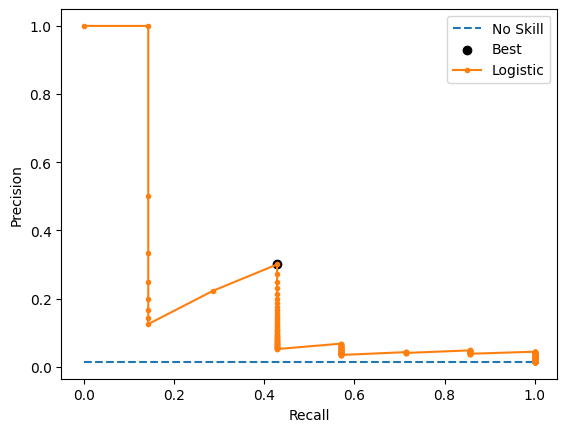

In [75]:
precision, recall, thresholds = metrics.precision_recall_curve(y_test, y_probas[:,1])

fscore = (2 * precision * recall) / (precision + recall)
ix = np.argmax(fscore) # locate the index of the largest f-measure
no_skill = len(y_test[y_test==1]) / len(y_test)

print(f'Best Threshold= {thresholds[ix]: .3f}, F-measure={fscore[ix]: .3f}\n')
print(f'Precision= {precision[ix]: .3f}, Recall= {recall[ix]: .3f}\n')
print(f'No Skill= {no_skill: .3f}\n\n')

plt.plot([0,1], [no_skill,no_skill], linestyle='--', label='No Skill')
plt.scatter(recall[ix], precision[ix], marker='o', color='black', label='Best')
plt.plot(recall, precision, marker='.', label='Logistic')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.legend()

In [76]:
pos_ratio = np.mean(y_test)
auroc = roc_auc_score(y_test, clf.predict_proba(X_test)[:, 1])
pr_auc = average_precision_score(y_test, clf.predict_proba(X_test)[:, 1])

print(f"AUROC Score: {auroc:.4f}")
print(f"PR-AUC Score: {pr_auc:.4f}")
print(f"양성비율: {pos_ratio:.4f}")

AUROC Score: 0.8690
PR-AUC Score: 0.2464
양성비율: 0.0140


### **2.2. Optimal Threshold Tuning**
Sometimes, we simply have a model and we wish to know the best threshold directly. In this case, we can define a set of thresholds and then evaluate predicted probabilities under each in order to find and select the optimal threshold.

In [77]:
probs = y_probas[:, 1]
thresholds = np.arange(0, 1, 0.001)
p, r, thresholds = metrics.precision_recall_curve(y_test, probs)

# DataFrame 생성 및 소수점 둘째 자리로 포맷 설정
df = pd.DataFrame({
    'Threshold': np.append(thresholds, 1.0),
    'Precision': p,
    'Recall': r
}).set_index('Threshold').T

# 소수점 둘째 자리까지만 표시
pd.set_option('display.float_format', lambda x: '%.2f' % x)
display(df)

Threshold,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.08,0.08,0.08,0.08,0.09,0.09,0.14,0.20,0.22,1.00
Precision,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,...,0.22,0.12,0.14,0.17,0.20,0.25,0.33,0.50,1.00,1.00
Recall,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,...,0.29,0.14,0.14,0.14,0.14,0.14,0.14,0.14,0.14,0.00


### 분류임계값에 따라 Positive 판정율 내리는 비율
- 재현율과 정밀도가 교차하는 지점이 오른쪽에 있을 수록 better estimator

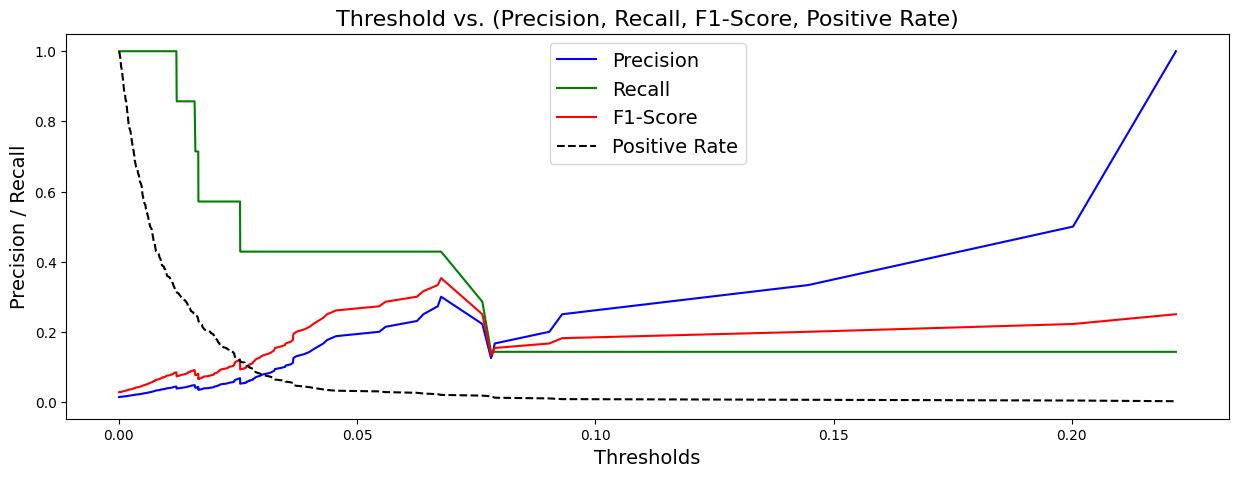

In [78]:
def to_labels(pos_probs, threshold):
    return (pos_probs >= threshold).astype('int')

scores = [np.sum(to_labels(probs, t)) / len(probs) for t in thresholds]

def plot_precision_recall_vs_threshold(precisions, recalls, thresholds):
    plt.rcParams["figure.figsize"] = (15, 5)
    plt.title('Threshold vs. (Precision, Recall, F1-Score, Positive Rate)', fontsize=16)
    plt.plot(thresholds, precisions[:-1], 'b-', label='Precision')
    plt.plot(thresholds, recalls[:-1], 'g-', label='Recall')
    plt.plot(thresholds, (2 * precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1]),
             'r-', label='F1-Score')
    plt.plot(thresholds, scores, 'k--', label='Positive Rate')
    plt.ylabel('Precision / Recall', fontsize=14)
    plt.xlabel('Thresholds', fontsize=14)
    plt.legend(loc='best', fontsize=14)

plot_precision_recall_vs_threshold(p, r, thresholds)

## 다양한 metrics로 Tuning

In [79]:
ftwo_scorer = metrics.make_scorer(metrics.fbeta_score, beta=2)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'recall_macro', ftwo_scorer]

params = {'C': np.logspace(-4, 4, 20), 'penalty': ['l1', 'l2']}
for score in scoring:
    grid = model_selection.RandomizedSearchCV(model, param_distributions=params, cv=5, scoring= score)
    print(f'예측 성능 지표= {score}')
    print('-'*70)
    y_predict = grid.fit(X_train, y_train).predict(X_test)
    print(metrics.classification_report(y_test, y_predict))
    print('-'*70)

예측 성능 지표= accuracy
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       493
           1       0.00      0.00      0.00         7

    accuracy                           0.99       500
   macro avg       0.49      0.50      0.50       500
weighted avg       0.97      0.99      0.98       500

----------------------------------------------------------------------
예측 성능 지표= precision
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       493
           1       0.00      0.00      0.00         7

    accuracy                           0.99       500
   macro avg       0.49      0.50      0.50       500
weighted avg       0.97      0.99      0.98       500

----------------------------------------------------------------------
예측 성능 지표= recall
------

## 손실함수 조정

In [ ]:
model = LogisticRegression(solver='lbfgs', class_weight='balanced')

params = {'C': np.logspace(-4, 4, 20), 'penalty': ['l1', 'l2']}
grid = model_selection.RandomizedSearchCV(model, params, cv=5, scoring= 'recall')
y_predict = grid.fit(X_train, y_train).predict(X_test)
print(metrics.classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       1.00      0.83      0.90       493
           1       0.06      0.71      0.10         7

    accuracy                           0.83       500
   macro avg       0.53      0.77      0.50       500
weighted avg       0.98      0.83      0.89       500



In [80]:
minor = np.sum(y)/len(y); major = 1- minor

model = LogisticRegression(solver='lbfgs', class_weight= {0: minor, 1: major})
params = {'C': np.logspace(-4, 4, 20), 'penalty': ['l1', 'l2']}
grid = model_selection.RandomizedSearchCV(model, params, cv=5, scoring= 'recall')
y_predict = grid.fit(X_train, y_train).predict(X_test)
y_probas = grid.fit(X_train, y_train).predict_proba(X_test)
print(metrics.classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00       493
           1       0.01      1.00      0.03         7

    accuracy                           0.01       500
   macro avg       0.01      0.50      0.01       500
weighted avg       0.00      0.01      0.00       500



In [81]:
y_probas.round(2)

array([[0.48, 0.52],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.48, 0.52],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.49, 0.51],
       [0.49, 0.51],
       [0.48, 0.52],
       [0.48,

<Figure size 1200x600 with 0 Axes>

Text(0.5, 1.0, 'Scatter Plot of Prediction Probabilities by Actual Class')

Text(0.5, 0, 'Sample Index')

Text(0, 0.5, 'Positive Prediction Probability')

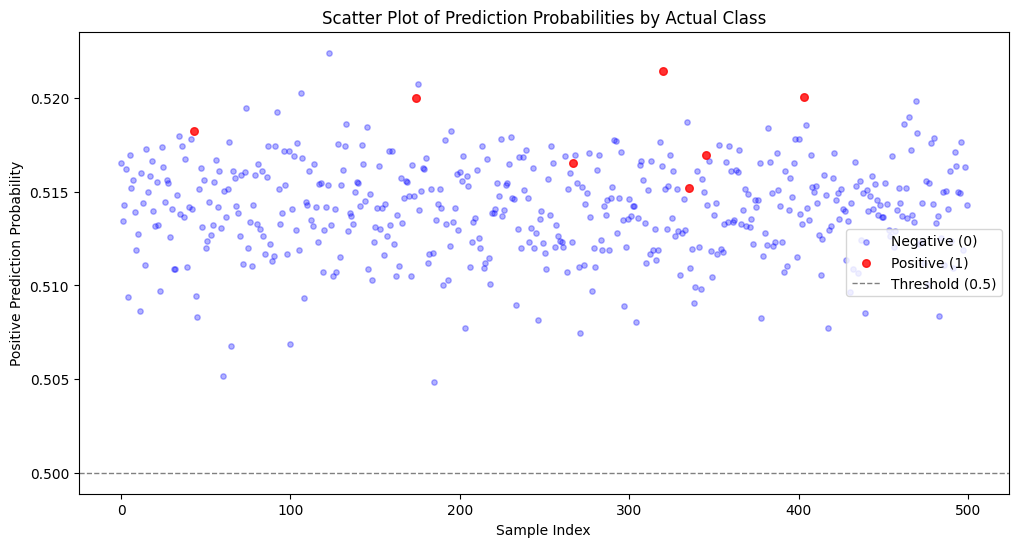

In [82]:
x_indices = np.arange(len(y_test))

plt.figure(figsize=(12, 6))

# Negative(0)와 Positive(1)를 나누어 산점도 그리기
plt.scatter(x_indices[y_test == 0], y_probas[y_test == 0, 1],
            color='blue', alpha=0.3, s=15, label='Negative (0)')
plt.scatter(x_indices[y_test == 1], y_probas[y_test == 1, 1],
            color='red', alpha=0.8, s=30, label='Positive (1)')

# 분류 기준 임계값(예: 0.5) 선 추가
plt.axhline(y=0.5, color='gray', linestyle='--', linewidth=1, label='Threshold (0.5)')

plt.title('Scatter Plot of Prediction Probabilities by Actual Class')
plt.xlabel('Sample Index')
plt.ylabel('Positive Prediction Probability')
plt.legend(loc='center right')
plt.show()

# END